# 30 - Synthetic Medical Records with a GAN: realistic, useful, and private?
**Topic:** Deep Learning  |  **Reference:** "Building Synthetic Medical Records using GANs" (amanxai.com, Aug 2025)

**Question.** Can a generative adversarial network (GAN) produce fake patient records that look and behave like real ones without exposing the real patients?

**Reference method:** train a GAN on a medical table and compare a few generated rows or distributions with the real ones.
**What I do:** use a real public medical table (**Pima Indians Diabetes**, 768 women, 8 measurements + a diabetes outcome) and compare **four ways to make synthetic data**: (1) *copying* real rows, (2) *shuffling each column independently*, (3) a **Gaussian copula** (a classical statistical generator), (4) a **WGAN-GP** (a GAN that trains stably). Each is scored on three axes that pull against each other: **fidelity** (does it look real?), **utility** (does a model trained on it work on real patients? "train on synthetic, test on real") and **privacy** (does it leak individuals? distance to the closest real record and a membership-inference attack).

## 1. Libraries and data

In [1]:
import warnings, os, json, joblib, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from scipy import stats
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
sns.set_theme(style="whitegrid", context="notebook")
torch.manual_seed(0); np.random.seed(0); torch.set_num_threads(1); os.makedirs("model", exist_ok=True)
cache = "../_data/pima.csv"
if os.path.exists(cache): df = pd.read_csv(cache)
else: df = fetch_openml(data_id=37, as_frame=True, parser="auto").frame; df.to_csv(cache, index=False)
df["outcome"] = (df["class"].astype(str).str.contains("positive")).astype(int); df = df.drop(columns="class"); df.columns = ["pregnancies", "glucose", "blood_pressure", "skin_thickness", "insulin", "bmi", "pedigree", "age", "outcome"]
NUM = list(df.columns[:-1]); INT = ["pregnancies", "glucose", "blood_pressure", "skin_thickness", "insulin", "age"]
print(df.shape, "| outcome (diabetes) rate: %.1f%%" % (df.outcome.mean() * 100)); df.head()

(768, 9) | outcome (diabetes) rate: 34.9%


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,pedigree,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Look at the data first

                  mean     std    min     50%     max
pregnancies       3.85    3.37   0.00    3.00   17.00
glucose         120.89   31.97   0.00  117.00  199.00
blood_pressure   69.11   19.36   0.00   72.00  122.00
skin_thickness   20.54   15.95   0.00   23.00   99.00
insulin          79.80  115.24   0.00   30.50  846.00
bmi              31.99    7.88   0.00   32.00   67.10
pedigree          0.47    0.33   0.08    0.37    2.42
age              33.24   11.76  21.00   29.00   81.00
outcome           0.35    0.48   0.00    0.00    1.00

share of exact zeros (physically impossible for a living patient, so these mean 'not measured'): {'glucose': 0.7, 'blood_pressure': 4.6, 'skin_thickness': 29.6, 'insulin': 48.7, 'bmi': 1.4}


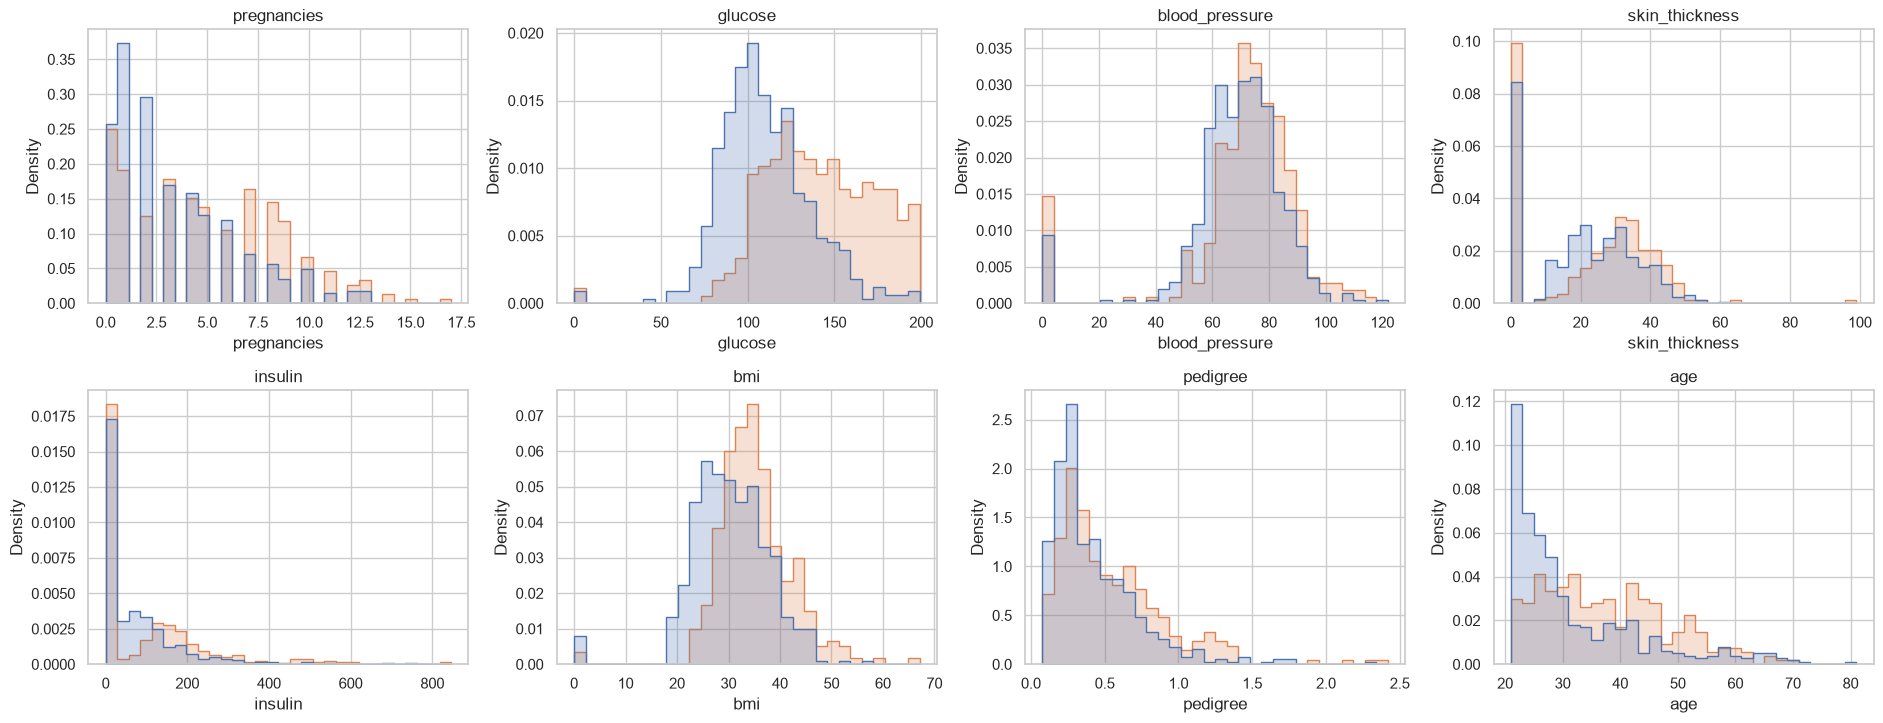

correlations with the outcome: {'pregnancies': 0.22, 'glucose': 0.47, 'blood_pressure': 0.07, 'skin_thickness': 0.07, 'insulin': 0.13, 'bmi': 0.29, 'pedigree': 0.17, 'age': 0.24}


In [2]:
print(df.describe().round(2).T[["mean", "std", "min", "50%", "max"]].to_string())
zeros = (df[["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]] == 0).mean() * 100; print("\nshare of exact zeros (physically impossible for a living patient, so these mean 'not measured'): %s" % zeros.round(1).to_dict())
fig, ax = plt.subplots(2, 4, figsize=(19, 7.4))
for a, c in zip(ax.ravel(), NUM): sns.histplot(data=df, x=c, hue="outcome", bins=30, ax=a, element="step", stat="density", common_norm=False); a.set_title(c); a.legend_.remove() if a.get_legend() else None
plt.tight_layout(); plt.show(); print("correlations with the outcome:", df.corr()["outcome"].drop("outcome").round(2).to_dict())

**Reading it.** 768 patients, 8 measurements, 34.9% with diabetes. The table has a well-known trap: **exact zeros that cannot be real** (a living patient does not have a blood pressure or BMI of 0). They mean "not measured": glucose 0.7%, blood pressure 4.6%, skin thickness 29.6%, **insulin 48.7%**. A generator that learns these columns has to reproduce a *point mass at zero* plus a continuous part. Glucose is the strongest single signal for the outcome (correlation 0.47), then BMI (0.29) and age (0.24). Reference level: models trained on the real training rows reach an AUC of **0.871** (logistic regression) and **0.850** (random forest) on the 231 real hold-out patients. Synthetic data is judged against that number.

## 3. Train/hold-out split and the real-data reference
Generators see only the **training** part (70%, 537 patients). The **hold-out** part (30%, 231 patients) is kept for the utility test and as the "new real people" reference for the privacy test. Reference utility: a model trained on real training data, tested on the hold-out ("TRTR").

In [3]:
tr, ho = train_test_split(df, test_size=0.3, stratify=df.outcome, random_state=0); tr, ho = tr.reset_index(drop=True), ho.reset_index(drop=True); print(len(tr), "train |", len(ho), "hold-out")
def utility(syn):
    out = {}
    for nm, mk in [("logistic regression", lambda: LogisticRegression(max_iter=2000)), ("random forest", lambda: RandomForestClassifier(300, min_samples_leaf=3, random_state=0, n_jobs=4))]:
        sc = StandardScaler().fit(syn[NUM]); m = mk().fit(sc.transform(syn[NUM]), syn.outcome); out[nm] = roc_auc_score(ho.outcome, m.predict_proba(sc.transform(ho[NUM]))[:, 1])
    return out
trtr = utility(tr); print("train on REAL, test on real hold-out (AUC):", {k: round(v, 3) for k, v in trtr.items()})

537 train | 231 hold-out


train on REAL, test on real hold-out (AUC): {'logistic regression': 0.871, 'random forest': 0.85}


## 4. Four generators
1. **Resample:** draw rows from the training data with replacement (a perfect-looking fake; the benchmark of what "no privacy" looks like).
2. **Independent columns:** shuffle each column on its own: correct one-column histograms, no relationships.
3. **Gaussian copula:** keep every column's distribution (empirical quantiles), model the dependence by the correlation of the normal scores, and sample.
4. **WGAN-GP:** a generator (noise of 32 numbers -> 128 -> 128 -> 9 outputs) against a critic (9 -> 128 -> 128 -> 1) trained with the Wasserstein loss and a gradient penalty (weight 10), 5 critic steps per generator step, on columns mapped to a normal shape with a quantile transform. The outcome is generated as a column and rounded to 0/1.

In [4]:
cols = NUM + ["outcome"]
def post(a, qt):
    d = pd.DataFrame(qt.inverse_transform(a), columns=cols)
    for c in INT: d[c] = d[c].round().clip(lower=0)
    d["outcome"] = (d.outcome > 0.5).astype(int); return d
def gen_resample(n, seed): return tr.sample(n, replace=True, random_state=seed).reset_index(drop=True)
def gen_indep(n, seed): r = np.random.RandomState(seed); return pd.DataFrame({c: r.choice(tr[c].to_numpy(), n) for c in cols})
class Copula:
    def __init__(self, d): self.d = d; z = stats.norm.ppf((d.rank(method="average") - 0.5) / len(d)); self.cov = np.corrcoef(z.T)
    def sample(self, n, seed):
        r = np.random.RandomState(seed); z = r.multivariate_normal(np.zeros(self.cov.shape[0]), self.cov, n); u = stats.norm.cdf(z); out = pd.DataFrame({c: np.quantile(self.d[c].to_numpy(), u[:, j]) for j, c in enumerate(self.d.columns)})
        for c in INT: out[c] = out[c].round()
        out["outcome"] = (out.outcome > 0.5).astype(int)
        return out
cop = Copula(tr); gen_copula = lambda n, seed: cop.sample(n, seed)
class G(nn.Module):
    def __init__(self, zd=32, o=9): super().__init__(); self.n = nn.Sequential(nn.Linear(zd, 128), nn.LeakyReLU(.2), nn.Linear(128, 128), nn.LeakyReLU(.2), nn.Linear(128, o))
    def forward(self, z): return self.n(z)
class Critic(nn.Module):
    def __init__(self, i=9): super().__init__(); self.n = nn.Sequential(nn.Linear(i, 128), nn.LeakyReLU(.2), nn.Linear(128, 128), nn.LeakyReLU(.2), nn.Linear(128, 1))
    def forward(self, x): return self.n(x)
def train_gan(seed, epochs=3000, bs=128, n_critic=5, lam=10.0):
    torch.manual_seed(seed); qt = QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=0).fit(tr[cols]); X = torch.tensor(qt.transform(tr[cols]), dtype=torch.float32)
    g, c = G(), Critic(); og = torch.optim.Adam(g.parameters(), 1e-4, betas=(0.5, 0.9)); oc = torch.optim.Adam(c.parameters(), 1e-4, betas=(0.5, 0.9)); log = []
    for ep in range(1, epochs + 1):
        for _ in range(n_critic):
            real = X[torch.randint(len(X), (bs,))]; fake = g(torch.randn(bs, 32)).detach(); a = torch.rand(bs, 1); mix = (a * real + (1 - a) * fake).requires_grad_(True)
            gp = ((torch.autograd.grad(c(mix).sum(), mix, create_graph=True)[0].norm(2, dim=1) - 1) ** 2).mean(); lc = c(fake).mean() - c(real).mean() + lam * gp; oc.zero_grad(); lc.backward(); oc.step()
        lg = -c(g(torch.randn(bs, 32))).mean(); og.zero_grad(); lg.backward(); og.step()
        if ep % 500 == 0: log.append((ep, float(-lc.item() + lam * gp.item())))
    return g, qt, log
t0 = time.time(); gans = [train_gan(s) for s in range(3)]; print("trained 3 GANs in %.0fs; critic distance estimates at epochs 500..3000 (seed 0):" % (time.time() - t0), [round(v, 3) for _, v in gans[0][2]])
def gen_gan_k(k):
    g, qt, _ = gans[k]
    return lambda n, seed: post(g(torch.randn(n, 32, generator=torch.Generator().manual_seed(seed))).detach().numpy(), qt)

trained 3 GANs in 778s; critic distance estimates at epochs 500..3000 (seed 0): [5.937, 2.076, 3.152, 3.604, 3.369, 3.613]


## 5. What the synthetic data look like

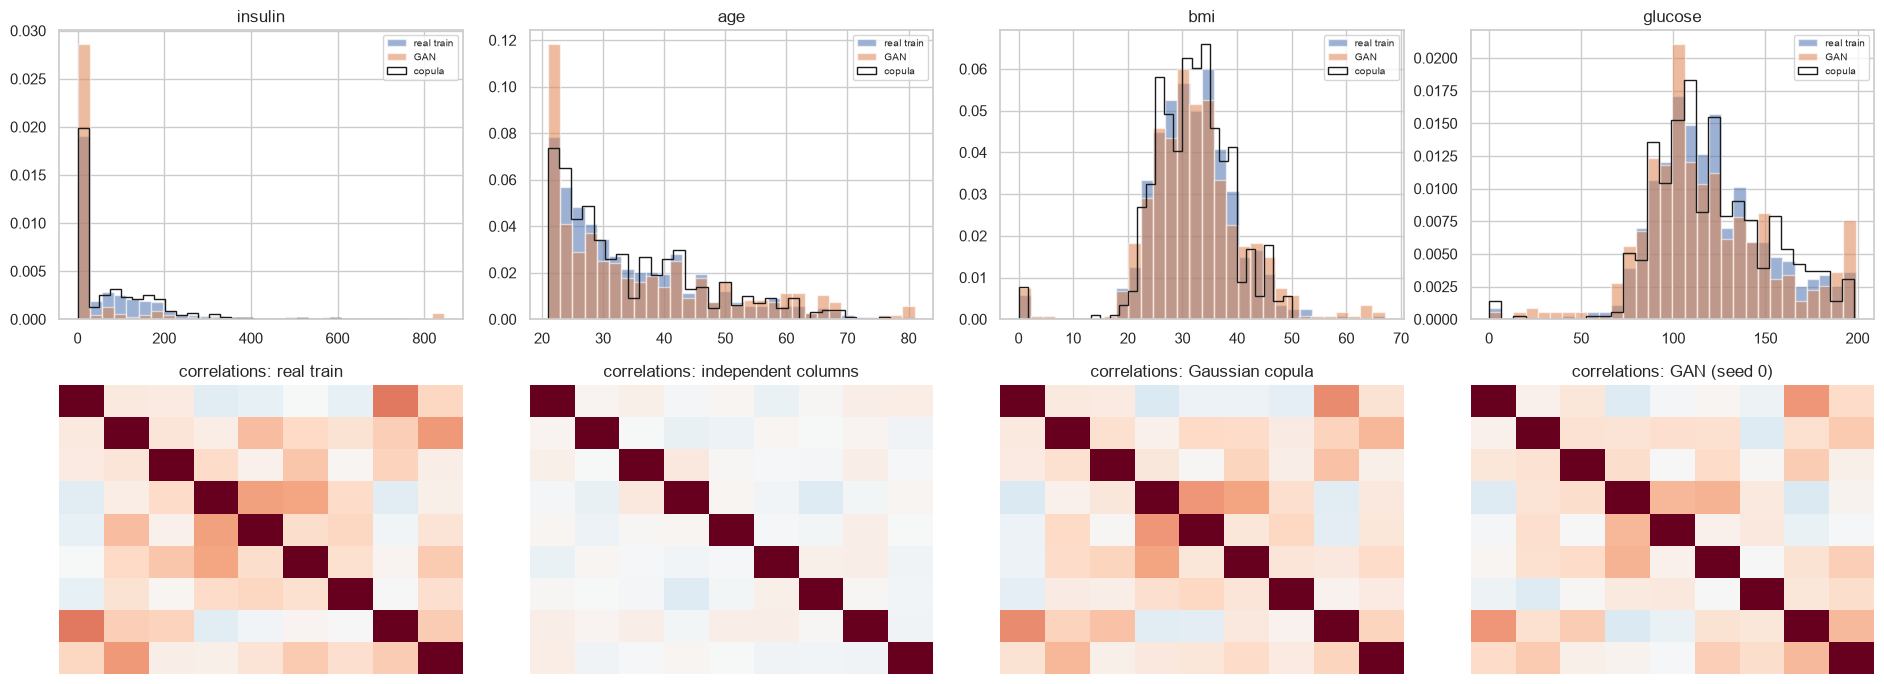

zeros in insulin (share): real 53% | GAN 80% | copula 49% | independent 51%


In [5]:
N = len(tr); S = {"resample": gen_resample(N, 1), "independent columns": gen_indep(N, 1), "Gaussian copula": gen_copula(N, 1), "GAN (seed 0)": gen_gan_k(0)(N, 1)}
fig, ax = plt.subplots(2, 4, figsize=(19, 7))
for a, c in zip(ax[0], ["insulin", "age", "bmi", "glucose"]):
    a.hist(tr[c], bins=30, alpha=.55, density=True, label="real train"); a.hist(S["GAN (seed 0)"][c], bins=30, alpha=.55, density=True, label="GAN"); a.hist(S["Gaussian copula"][c], bins=30, histtype="step", density=True, label="copula", color="k"); a.set_title(c); a.legend(fontsize=7)
for a, (nm, d) in zip(ax[1], [("real train", tr), ("independent columns", S["independent columns"]), ("Gaussian copula", S["Gaussian copula"]), ("GAN (seed 0)", S["GAN (seed 0)"])]): sns.heatmap(d.corr(), cmap="RdBu_r", vmin=-1, vmax=1, ax=a, cbar=False, xticklabels=False, yticklabels=False); a.set_title("correlations: " + nm)
plt.tight_layout(); plt.show()
print("zeros in insulin (share): real %.0f%% | GAN %.0f%% | copula %.0f%% | independent %.0f%%" % tuple((d.insulin == 0).mean() * 100 for d in (tr, S["GAN (seed 0)"], S["Gaussian copula"], S["independent columns"])))

**Reading it.** *Independent columns* (shuffling each column separately) keeps every histogram but destroys the correlations (second heat-map is almost blank), so rows are impossible combinations. The *Gaussian copula* keeps both. The GAN gets the broad shapes and correlation pattern right but has visible faults: **80% of its insulin values are zero against 53% in the real data** (it exaggerates the point mass), the age histogram has a spike at 21 (the minimum), and glucose and BMI spread values into regions where the real data has almost nothing (glucose 20-60, BMI above 55). The copula follows the real histograms more closely.

## 6. Scoring: fidelity, utility, privacy
* **Fidelity** - `KS`: the average over the 8 measurements of the Kolmogorov-Smirnov distance between real-train and synthetic one-column distributions (0 = identical); `corr diff`: Frobenius norm of the difference of correlation matrices; `distinguisher AUC`: a random forest tries to tell real-train from synthetic rows (cross-validated; 0.5 = cannot tell).
* **Utility** - `TSTR AUC`: train on synthetic data only, test on real hold-out (compare with the TRTR reference above).
* **Privacy** - `DCR`: the distance (in standardised units) from each synthetic row to its nearest *real training* row; shown as the median and the share of synthetic rows within 0.05 of a real row (near-copies). For scale, the same distance is computed for the **hold-out patients** (new real people, who are *not* copies). **Membership attack AUC:** an attacker who sees only the synthetic data guesses that a record was in the training set when it is very close to some synthetic row (AUC 0.5 = no information; 1.0 = full leak).

In [6]:
scaler = StandardScaler().fit(tr[NUM]); Ztr = scaler.transform(tr[NUM])
def dcr(a, b):
    A, Bm = scaler.transform(a[NUM]), scaler.transform(b[NUM]); out = np.empty(len(A))
    for i0 in range(0, len(A), 200): d = ((A[i0:i0 + 200, None, :] - Bm[None]) ** 2).sum(-1); out[i0:i0 + 200] = np.sqrt(d.min(1))
    return out
ks = lambda s: float(np.mean([stats.ks_2samp(tr[c], s[c]).statistic for c in NUM]))
cd = lambda s: float(np.linalg.norm(tr.corr().to_numpy() - s.corr().fillna(0).to_numpy()))
def distinguish(s):
    X_ = pd.concat([tr, s]); y_ = np.r_[np.zeros(len(tr)), np.ones(len(s))]; p = cross_val_predict(RandomForestClassifier(200, min_samples_leaf=3, random_state=0, n_jobs=4), X_, y_, cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1]; return roc_auc_score(y_, p)
def privacy(s):
    d_syn = dcr(s, tr); d_hold = dcr(ho, tr); mem = dcr(tr, s); non = dcr(ho, s); y_ = np.r_[np.ones(len(mem)), np.zeros(len(non))]
    return {"DCR median": float(np.median(d_syn)), "near-copies %": float((d_syn < 0.05).mean() * 100), "hold-out DCR median (reference)": float(np.median(d_hold)), "membership AUC": float(roc_auc_score(y_, -np.r_[mem, non]))}
def score(s):
    u = utility(s); return {"KS": ks(s), "corr diff": cd(s), "distinguisher AUC": distinguish(s), "TSTR LR AUC": u["logistic regression"], "TSTR RF AUC": u["random forest"], **privacy(s)}
rows = {k: score(v) for k, v in S.items()}
for k in (1, 2): rows[f"GAN (seed {k})"] = score(gen_gan_k(k)(N, 1))
SC = pd.DataFrame(rows).T; SC.loc["real hold-out (reference)"] = {"KS": ks(ho), "corr diff": cd(ho), "distinguisher AUC": np.nan, "TSTR LR AUC": trtr["logistic regression"], "TSTR RF AUC": trtr["random forest"], "DCR median": float(np.median(dcr(ho, tr))), "near-copies %": float((dcr(ho, tr) < 0.05).mean() * 100), "hold-out DCR median (reference)": float(np.median(dcr(ho, tr))), "membership AUC": np.nan}
print(SC.round(3).to_string())

                              KS  corr diff  distinguisher AUC  TSTR LR AUC  TSTR RF AUC  DCR median  near-copies %  hold-out DCR median (reference)  membership AUC
resample                   0.029      0.355              0.229        0.872        0.837       0.000          100.0                            1.016           0.823
independent columns        0.030      1.849              0.803        0.279        0.480       1.327            0.0                            1.016           0.514
Gaussian copula            0.032      0.423              0.587        0.854        0.800       1.145            0.0                            1.016           0.484
GAN (seed 0)               0.127      0.760              0.749        0.856        0.810       1.230            0.0                            1.016           0.523
GAN (seed 1)               0.112      0.799              0.764        0.869        0.807       1.218            0.0                            1.016           0.514
GAN (seed 

**Reading it (hold-out = 231 real patients; synthetic sets have 537 rows).**
* **Fidelity.** Column by column the copula (KS distance 0.032) is as close as resampling (0.029) and four times closer than the GAN (0.112-0.131; for comparison, real hold-out patients are at 0.077 from the training set). The GAN's correlation matrix is also further off than the copula's in all three runs (corr diff 0.76 / 0.80 / 0.62 vs 0.42). A random forest can tell GAN rows from real ones with an AUC of about 0.75-0.76; for the copula it is 0.59, i.e. harder to spot. The distinguisher figure for *resample* (0.23) is an artefact, not a good result: each fake row is an exact twin of a real row, so cross-validation sees the same row on both sides with opposite labels. Treat it as undefined.
* **Utility (train on synthetic, test on real).** Resample 0.872 (LR) and 0.837 (RF), the copula 0.854 and 0.800, the GAN 0.843-0.869 (LR) and 0.807-0.812 (RF) over three seeds, against 0.871 and 0.850 for real data. **The GAN is not better than the much simpler copula**; the spread between GAN seeds (0.026 in LR AUC) is about as large as the gap between the GAN and the copula. *Independent columns* give an LR AUC of **0.28**, below chance: with outcome shuffled away from the measurements the model learns an arbitrary direction, which for these data can point the wrong way. That number is an accident of the arbitrary direction, not a property of the method.
* **Privacy.** Resample leaks by construction: 100% exact copies, membership attack AUC 0.82. The other four generators produce no near-copies (< 0.05) and membership AUCs of 0.48-0.52, i.e. the attack cannot tell members from non-members.

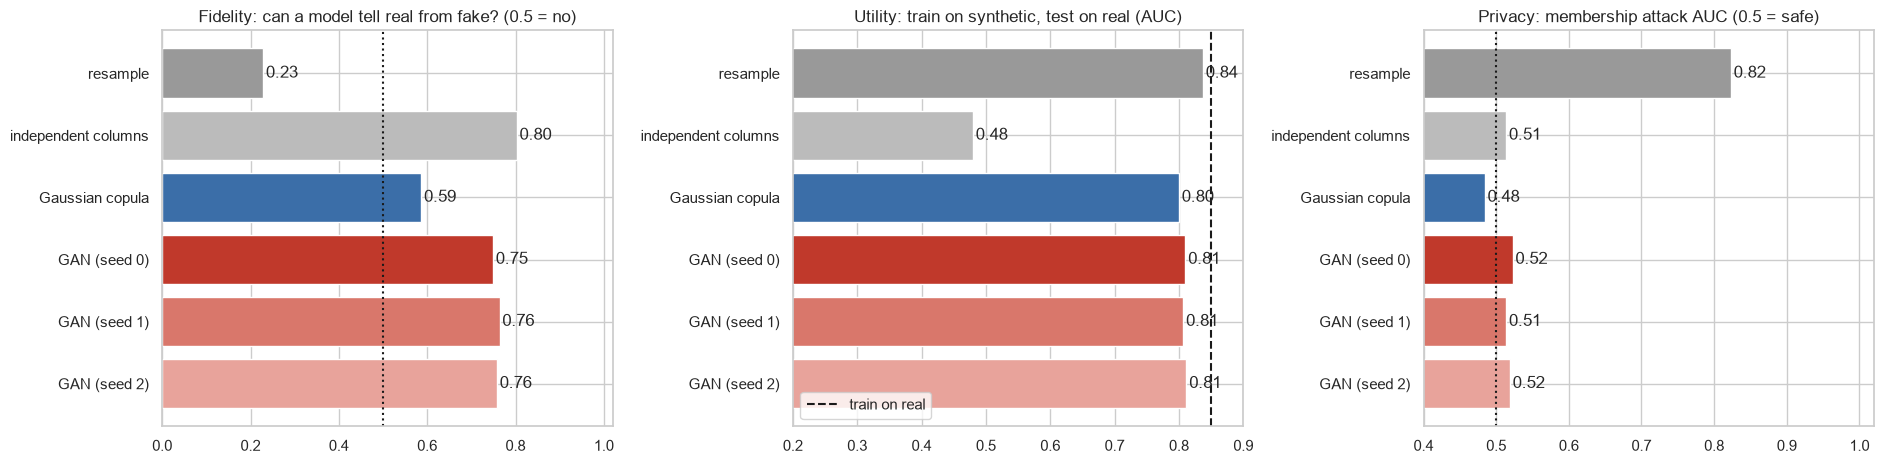

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8)); order = ["resample", "independent columns", "Gaussian copula", "GAN (seed 0)", "GAN (seed 1)", "GAN (seed 2)"]; sub = SC.loc[order]; colr = ["#999", "#bbb", "#3b6ea8", "#c0392b", "#d9776b", "#e8a39b"]
ax[0].barh(order[::-1], sub["distinguisher AUC"][::-1], color=colr[::-1]); ax[0].axvline(.5, color="k", ls=":"); ax[0].set_xlim(0, 1.02); ax[0].bar_label(ax[0].containers[0], fmt="%.2f", padding=2); ax[0].set_title("Fidelity: can a model tell real from fake? (0.5 = no)")
ax[1].barh(order[::-1], sub["TSTR RF AUC"][::-1], color=colr[::-1]); ax[1].axvline(trtr["random forest"], color="k", ls="--", label="train on real"); ax[1].set_xlim(.2, .9); ax[1].bar_label(ax[1].containers[0], fmt="%.2f", padding=2); ax[1].legend(loc="lower left"); ax[1].set_title("Utility: train on synthetic, test on real (AUC)")
ax[2].barh(order[::-1], sub["membership AUC"][::-1], color=colr[::-1]); ax[2].axvline(.5, color="k", ls=":"); ax[2].set_xlim(.4, 1.02); ax[2].bar_label(ax[2].containers[0], fmt="%.2f", padding=2); ax[2].set_title("Privacy: membership attack AUC (0.5 = safe)")
plt.tight_layout(); plt.show()

## 7. A closer look at privacy: the nearest real patient
For the GAN, the distribution of distances to the nearest real training patient, against the same distance for real hold-out patients and for the copy/resample generator.

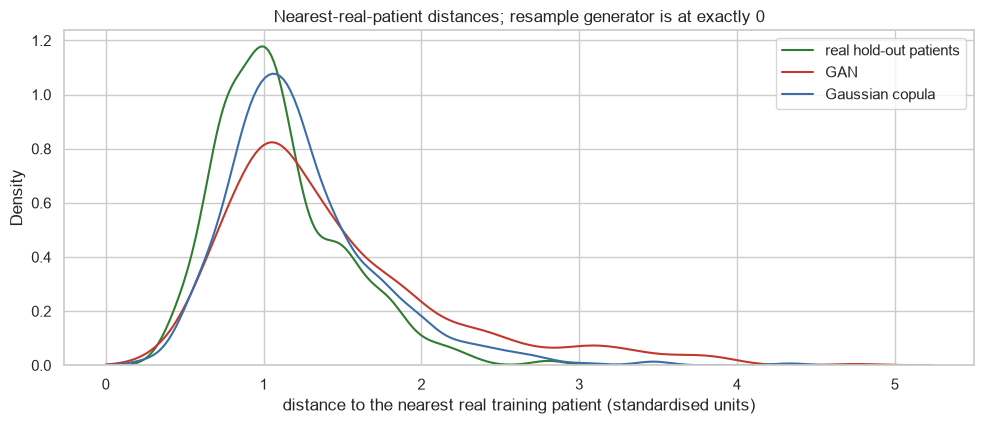

closest synthetic-to-real distances: GAN 0.293, copula 0.256, resample 0.000; hold-out patients 0.407


In [8]:
d_gan, d_res, d_ho, d_cop = dcr(S["GAN (seed 0)"], tr), dcr(S["resample"], tr), dcr(ho, tr), dcr(S["Gaussian copula"], tr)
fig, ax = plt.subplots(figsize=(10, 4.4))
for d, l, c in [(d_ho, "real hold-out patients", "#2e7d32"), (d_gan, "GAN", "#c0392b"), (d_cop, "Gaussian copula", "#3b6ea8")]: sns.kdeplot(d, ax=ax, label=l, color=c, bw_adjust=.8, clip=(0, None))
ax.set_xlabel("distance to the nearest real training patient (standardised units)"); ax.set_title("Nearest-real-patient distances; resample generator is at exactly 0"); ax.legend(); plt.tight_layout(); plt.show()
print("closest synthetic-to-real distances: GAN %.3f, copula %.3f, resample %.3f; hold-out patients %.3f" % (d_gan.min(), d_cop.min(), d_res.min(), d_ho.min()))

**Reading it.** The median distance of a synthetic patient to the nearest real training patient is 1.23 (GAN) and 1.15 (copula) standardised units, a bit *larger* than the 1.02 of genuinely new real patients, and the closest GAN/copula/real-holdout pairs are 0.29, 0.26 and 0.41. The GAN's right tail (distances 2.5-4) reflects rows that look implausible rather than rows that are safely anonymous. So the two good generators do not copy; resample plainly does. **This is one simple attack (nearest distance) on one small data set.** A low membership AUC is not a privacy guarantee: no differential privacy was used, rare records (the very high insulin or pedigree values) are the ones most at risk, and a stronger attacker might do better. Synthetic data of this kind should still be handled as sensitive until a formal analysis says otherwise.

## 8. Save

In [9]:
g0, qt0, _ = gans[0]; torch.save(g0.state_dict(), "model/gan_generator.pt"); joblib.dump({"quantile_transformer": qt0, "columns": cols, "integer_columns": INT, "copula_corr": cop.cov, "train": tr}, "model/gan_support.joblib")
S["GAN (seed 0)"].to_csv("model/gan_synthetic_sample.csv", index=False); json.dump({"scores": SC.round(4).to_dict("index"), "trtr": trtr}, open("model/meta.json", "w"), indent=1); print(os.listdir("model"))

['gan_generator.pt', 'gan_support.joblib', 'gan_synthetic_sample.csv', 'meta.json']


## 9. Summary: my approach vs the reference
| | Reference (as I understood it) | This notebook |
|---|---|---|
| Question | can a GAN make medical-looking rows? | is the synthetic table realistic **and** useful **and** private, and does the GAN beat simple generators? |
| Generators | one GAN | resample (copy), independent columns, **Gaussian copula**, **WGAN-GP** (3 seeds) |
| Checks | look at samples / distributions | fidelity (KS, correlations, a classifier that tries to tell real from fake), utility (train on synthetic, test on real) and privacy (nearest real patient, membership attack) |
| Result | plausible rows | copula and GAN reach about the same utility (AUC 0.85 LR vs real-data 0.87); **the copula is the more faithful**, the GAN exaggerates zero insulin (80% vs 53%) and spreads into implausible ranges; copying wins on fidelity and fails privacy (membership AUC 0.82) |

**What I learned.** (1) Fidelity, utility and privacy are three different questions and the trivial generator (copy the rows) wins two of them and fails the third, so a single "looks real" check says little. (2) A GAN is not automatically better than a classical statistical model on a small table of 768 rows: it needed 16 minutes of training for three seeds and was less faithful than a copula that needs no training loop. (3) Missing values coded as zero must be treated before generation, or the generator learns the coding. (4) Baselines that should fail (independent columns) are useful: they showed that the utility score depends on the dependence between columns.

**Limits.** 768 patients; one table; 3 GAN seeds; one simple privacy attack and no formal guarantee; utility measured on a single outcome with two classifiers; the hold-out set is only 231 patients (AUC differences of 0.02 are inside the noise). **Next step:** impute the zeros first, try conditional tabular GANs and a differentially-private variant, and add a stronger membership attack.